## Getting back to the ranking of Features by Correlation

In [4]:
import pandas as pd 
import os 

# print(os.getcwd())
os.chdir("../data/")
# print(os.getcwd())

psalms = pd.read_csv("offical_psalms_data.csv")
psalms

/Users/caden/anaconda3/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.4' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/Users/caden/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


,Unnamed: 0,text_Psalter,psalm_num,verse,neg,neu,pos,compound,polarity,subjectivity,...,syllable_count,avg_syllables_per_word,polysyllable_count,num_sentences,avg_words_sent,kathisma_num,bertTopic,vader_category_Negative,vader_category_Neutral,vader_category_Positive
0,0,0,1,Blessed is the man Who walks not in the counse...,0.015,0.920,0.064,0.7783,0.000000,0.000000,...,163,1.225564,8,6,22.166667,1.0,0,0,0,1
1,2,0,2,Why do the nations rage And the people meditat...,0.120,0.787,0.093,-0.6486,-0.153333,0.400000,...,255,1.281407,12,12,16.583333,1.0,3,1,0,0
2,4,0,3,A psalm by David when he fled from the face of...,0.089,0.786,0.126,0.8020,0.048889,0.437778,...,183,1.220000,7,8,18.750000,1.0,1,0,0,1
3,6,0,4,For the End in psalms an ode by David You hear...,0.092,0.748,0.159,0.8919,0.178571,0.600000,...,189,1.145455,4,8,20.625000,1.0,1,0,0,1
4,8,0,5,For the End concerning the inheritance a psalm...,0.130,0.712,0.157,0.7774,0.075000,0.593750,...,309,1.245968,14,12,20.666667,1.0,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
296,591,1,146,Alleluia of Aggeus and Zacharias Praise the Lo...,0.095,0.765,0.141,0.8417,0.157407,0.481481,...,232,1.260870,10,11,16.727273,20.0,2,0,0,1
297,593,1,147,Alleluia of Aggeus and Zacharias Praise the Lo...,0.000,0.794,0.206,0.9808,-0.200000,0.650000,...,156,1.300000,4,9,13.333333,20.0,-1,0,0,1
298,595,1,148,Alleluia of Aggeus and Zacharias Praise the Lo...,0.018,0.749,0.233,0.9946,0.116667,0.316667,...,258,1.277228,10,14,14.428571,20.0,2,0,0,1
299,597,1,149,Let Israel be glad in Him who made him And let...,0.017,0.759,0.224,0.9870,0.265455,0.664848,...,177,1.282609,6,9,15.333333,20.0,2,0,0,1


In [5]:
# calculating correlations 
corr = psalms.corr(numeric_only=True)#['berTopic']

# pulling the column of correlations to the text - 'Bible' or 'Psalter'
correlations = corr['text_Psalter'].sort_values(key=abs, ascending=False)

correlations = pd.DataFrame(correlations)
correlations = correlations[2:]
# correlations

### Preparing the Data

In [6]:
# from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Perceptron
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score


X = psalms[['neg', 'neu', 'pos', 'compound', 'polarity', 'subjectivity', 'emotional_score', 'fk_score',
       'gf_score', 'smog_score', 'word_count', 'avg_word_len', 'syllable_count', 'avg_syllables_per_word', 
       'polysyllable_count', 'num_sentences', 'avg_words_sent', 'kathisma_num', 'bertTopic',
       'vader_category_Negative', 'vader_category_Neutral', 'vader_category_Positive']]

y = psalms['text_Psalter']

#Splitting the dataset to train data and test data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

**---**
# Overall Goal of This Notebook
---
In the `modeling` notebook, the top 5 most correlated features proved to be the most successful for building a perceptron model. I am going to work at engineering the model to be the best that it can for the final work to the thesis and paper, as a whole.

## The best model from the `modeling` Notebook

In [7]:
def perceptron_trial(n=2):

    features = correlations[:n].index.tolist()
    X = psalms[features]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    perceptron = Perceptron(max_iter=100, eta0=0.1, random_state=42)
    perceptron.fit(X_train, y_train)

    y_pred = perceptron.predict(X_test)

    class_report = classification_report(
        y_test, y_pred, output_dict=True, zero_division=0
    )

    # Extract accuracy
    accuracy = class_report.pop("accuracy")

    # Convert remaining metrics into a DataFrame
    report_df = pd.DataFrame(class_report).T

    # Add accuracy as a column
    report_df["accuracy"] = accuracy
    report_df["features_used"] = str(features)
    report_df["n_features"] = n

    return report_df


result_df = perceptron_trial(n=5)
display(result_df)

,precision,recall,f1-score,support,accuracy,features_used,n_features
0,0.714286,0.322581,0.444444,31.0,0.590164,"['subjectivity', 'compound', 'neg', 'vader_cat...",5
1,0.553191,0.866667,0.675325,30.0,0.590164,"['subjectivity', 'compound', 'neg', 'vader_cat...",5
macro avg,0.633739,0.594624,0.559885,61.0,0.590164,"['subjectivity', 'compound', 'neg', 'vader_cat...",5
weighted avg,0.635059,0.590164,0.557992,61.0,0.590164,"['subjectivity', 'compound', 'neg', 'vader_cat...",5


The current **F1-Score** for the **macro-average** is a `0.559885`.

My goal is to get this metric as high as possdible, but hopefully above, or as close to, a `0.6`. There definetely is a difference between a Psalm from the Bible and the exact same Psalm from the Psalter, but they are not different enough for a model to acheive perfect accuaracy with the data that I have dervied in this research. 

The 5 features that will be focused on for this are the following: 

> - subjectivity 
> - compound
> - neg
> - vader_category_Negative
> - vader_category_Positive	

There are 5 different features to expereiment with and the first avenue that is going to be tried is turning them into a set of different combinatinos that try to get away from just a Perceptron on linear relationship.  

Adding every combination of 5 choose two to the 5 regular features. This is to see if there is an improved model. 

In [8]:
target_features = correlations[:5].index.tolist()
target_features

['subjectivity',
 'compound',
 'neg',
 'vader_category_Negative',
 'vader_category_Positive']

In [9]:
target_features_df = psalms[target_features]

In [10]:
def combo_columns(df, feat_1, feat_2):

    altered_feature = pd.DataFrame(index=df.index)

    col_name = f"{feat_1} & {feat_2}"

    altered_feature[col_name] = df[feat_1] * df[feat_2]

    new_features = df.copy()
    new_features[col_name] = altered_feature[col_name]

    return new_features, col_name

In [11]:
# testing 
combo_columns(target_features_df, 'compound', 'neg')

(     subjectivity  compound    neg  vader_category_Negative  \
 0        0.000000    0.7783  0.015                        0   
 1        0.400000   -0.6486  0.120                        1   
 2        0.437778    0.8020  0.089                        0   
 3        0.600000    0.8919  0.092                        0   
 4        0.593750    0.7774  0.130                        0   
 ..            ...       ...    ...                      ...   
 296      0.481481    0.8417  0.095                        0   
 297      0.650000    0.9808  0.000                        0   
 298      0.316667    0.9946  0.018                        0   
 299      0.664848    0.9870  0.017                        0   
 300      0.650000    0.9930  0.000                        0   
 
      vader_category_Positive  compound & neg  
 0                          1        0.011674  
 1                          0       -0.077832  
 2                          1        0.071378  
 3                          1        0

---
#### Function to engineer new columns to input as "new_features" to a perceptron model. 
Things to add: 
- passing in the entrie df of features from the `combo_columns(feat_1, feat_2)`

In [12]:
def perceptron_trial(X, new_feature):
    
    # defining the features being used
    features = X.columns.tolist()
    
    # Separate target and predictors
    y = psalms['text_Psalter']
    

    # Keep numeric predictors only
    # X = X.select_dtypes(include='number')

    # Calculate number of features
    n = X.shape[1]

    # Split data
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    perceptron = Perceptron(max_iter=100, eta0=0.1, random_state=42)
    perceptron.fit(X_train, y_train)
    
    
    y_pred = perceptron.predict(X_test)

    class_report = classification_report(
        y_test, y_pred, output_dict=True, zero_division=0
    )

    # Extract accuracy
    accuracy = class_report.pop("accuracy")

    # Convert remaining metrics into a DataFrame
    report_df = pd.DataFrame(class_report).T

    # Add accuracy as a column
    report_df["accuracy"] = accuracy
    report_df["features_used"] = str(features)
    report_df["new_feature"] = new_feature
    report_df["n_features"] = n

    return report_df.reset_index().rename(columns={'index': 'classifier'})


result_df = perceptron_trial(target_features_df, 'test')
display(result_df)

,classifier,precision,recall,f1-score,support,accuracy,features_used,new_feature,n_features
0,0,0.714286,0.322581,0.444444,31.0,0.590164,"['subjectivity', 'compound', 'neg', 'vader_cat...",test,5
1,1,0.553191,0.866667,0.675325,30.0,0.590164,"['subjectivity', 'compound', 'neg', 'vader_cat...",test,5
2,macro avg,0.633739,0.594624,0.559885,61.0,0.590164,"['subjectivity', 'compound', 'neg', 'vader_cat...",test,5
3,weighted avg,0.635059,0.590164,0.557992,61.0,0.590164,"['subjectivity', 'compound', 'neg', 'vader_cat...",test,5


With these updates lets integrate `combo_columns(feat_1, feat_2)` into a perceptron trial.

In [13]:
def new_trial(original_df, feature_1, feature_2, add_origin=True):

    new_features, new_col_name = combo_columns(
        original_df, feature_1, feature_2
    )
    
    # running a perceptron trial without the new column to include a a base line 
    if add_origin: 
        base = perceptron_trial(original_df, "baseline test")
        new_results = perceptron_trial(new_features, new_col_name)

        return pd.concat([base, new_results], axis=0, ignore_index=True)

    return perceptron_trial(new_features, new_col_name)
# Testing 
'''With the feature combination of  vader_category_Positive and coumpound as the 
   new engineered feature'''

results = new_trial(target_features_df, 'compound', 'neg', True) #boolean was used to debug find_best_f1()

I want to be able to see if the new feature engineering improved the model. The function below will help to see if the addition improved the f1-score of the mac avg. 

In [14]:
# max F1-score with  applying one new feature column per each perceptron trained
def find_best_f1(results_df):

    # Filter for macro average rows
    macro_results = results_df[
        results_df['classifier'] == 'macro avg'
    ]

    # Find index of highest F1-score
    best_idx = macro_results['f1-score'].idxmax()

    # Return entire row
    return results_df.loc[best_idx]


In [15]:
# getting the best F1-Score 
find_best_f1(results)

classifier                                               macro avg
precision                                                 0.621528
recall                                                    0.594086
f1-score                                                  0.567376
support                                                       61.0
accuracy                                                  0.590164
features_used    ['subjectivity', 'compound', 'neg', 'vader_cat...
new_feature                                         compound & neg
n_features                                                       6
Name: 6, dtype: object

### Making Progress!

With only this trial of adding a the engineer feature of $ \textbf{compound & neg}$ we can already see an inrcrease of **F1-Score** for the **macro-average** to a `0.567376`. We can now see how adding every combination of the 5 targeted features affects the model. We can then see if adding 2 or more engineered feature columns contributes to the success of the `Perceptron Model`

#### Further Notes

`eng_df` is the new dataframe that is outputed from the function  `combo_columns()`. 

In [16]:
import itertools

def feature_trial(eng_df, results_df):
    """
    Iterates through all unique pairs of features, generates new
    interaction features, and evaluates each combination using
    perceptron trials.

    Parameters
    ----------
    eng_df : pandas.DataFrame
        DataFrame containing the features used to generate pairwise
        combinations.

    results_df : pandas.DataFrame
        DataFrame used to store the results of each feature trial.

    Returns
    -------
    pandas.DataFrame
        Combined results from all perceptron trials, including the
        evaluation metrics and newly engineered features.
    """

    pairs = list(itertools.combinations(eng_df.columns, 2))

    for idx, pair in enumerate(pairs, 1):
        new_results = new_trial(eng_df, pair[0], pair[1])

        results_df = pd.concat(
            [results_df, new_results],
            axis=0,
            ignore_index=True
        )

    return results_df

In [17]:
target_features_df

,subjectivity,compound,neg,vader_category_Negative,vader_category_Positive
0,0.000000,0.7783,0.015,0,1
1,0.400000,-0.6486,0.120,1,0
2,0.437778,0.8020,0.089,0,1
3,0.600000,0.8919,0.092,0,1
4,0.593750,0.7774,0.130,0,1
...,...,...,...,...,...
296,0.481481,0.8417,0.095,0,1
297,0.650000,0.9808,0.000,0,1
298,0.316667,0.9946,0.018,0,1
299,0.664848,0.9870,0.017,0,1


In [18]:
full_results = pd.DataFrame() 

# reminder that combo_columns returns a tuple of data
new_features, name = combo_columns(target_features_df, 'compound', 'neg')

results_with_engineering = feature_trial(new_features, full_results)

In [19]:
new_features

,subjectivity,compound,neg,vader_category_Negative,vader_category_Positive,compound & neg
0,0.000000,0.7783,0.015,0,1,0.011674
1,0.400000,-0.6486,0.120,1,0,-0.077832
2,0.437778,0.8020,0.089,0,1,0.071378
3,0.600000,0.8919,0.092,0,1,0.082055
4,0.593750,0.7774,0.130,0,1,0.101062
...,...,...,...,...,...,...
296,0.481481,0.8417,0.095,0,1,0.079962
297,0.650000,0.9808,0.000,0,1,0.000000
298,0.316667,0.9946,0.018,0,1,0.017903
299,0.664848,0.9870,0.017,0,1,0.016779


In [20]:
find_best_f1(results_with_engineering)

classifier                                               macro avg
precision                                                 0.649275
recall                                                    0.610753
f1-score                                                  0.581236
support                                                       61.0
accuracy                                                  0.606557
features_used    ['subjectivity', 'compound', 'neg', 'vader_cat...
new_feature                     compound & vader_category_Negative
n_features                                                       7
Name: 54, dtype: object

## Accidental Find!

- Found an f1-score with a `0.581236` while rerunning a bunch of cells. Before rerunning the notebook I wanted to record these so if they dont come up in a fresh new run I can write further code to achive that results, now that I know it exists. 
- As a further Clarification this 'accident" was actualy intention in the way of the fact that `compound` and `vader_category_negative` were assigned as a pair within, 

    ```python
     pairs = list(itertools.combinations(eng_df.columns, 2))
        for idx, pair in enumerate(pairs, 1):
            new_results = new_trial(eng_df, pair[0], pair[1])
    ```
of the `feature_trial()` function. I did not fully see this results maybe due the fact of running the cells so many times. Below is a further summary of the model and the results from all 4 of the classifiers.

**Features used:**

    "['subjectivity', 'compound', 'neg', 'vader_category_Negative', 'vader_category_Positive', 'compound & neg', 'compound & vader_category_Negative']"
    
Below is a full table of the row 

| Metric                | Value                                                      |
| --------------------- | ---------------------------------------------------------- |
| Precision (Macro Avg) | 0.649275                                                   |
| Recall (Macro Avg)    | 0.610753                                                   |
| F1-Score (Macro Avg)  | 0.581236                                                   |
| Support               | 61                                                         |
| Accuracy              | 0.606557                                                   |
| Features Used         | `['subjectivity', 'compound', 'neg', 'vader_category...']` |
| New Feature           | `compound & vader_category_Negative`                       |
| Number of Features    | 7                                                          |

I am going to pull the table with all four columns of this model to see if there is anything wrong with the individual classifiers. 
| **Classifier** | **Precision** | **Recall** | **F1-Score** | **Support** | **Accuracy** | **Features Used** | **New Feature** | **N Features** |
|---|---:|---:|---:|---:|---:|---|---|---:|
| **0** | 0.733333 | 0.354839 | 0.478261 | 31 | 0.606557 | `['subjectivity', 'compound', 'neg', 'vader_cat...']` | `compound & vader_category_Negative` | 7 |
| **1** | 0.565217 | 0.866667 | 0.684211 | 30 | 0.606557 | `['subjectivity', 'compound', 'neg', 'vader_cat...']` | `compound & vader_category_Negative` | 7 |
| **Macro Avg** | 0.649275 | 0.610753 | 0.581236 | 61 | 0.606557 | `['subjectivity', 'compound', 'neg', 'vader_cat...']` | `compound & vader_category_Negative` | 7 |
| **Weighted Avg** | 0.650653 | 0.606557 | 0.579548 | 61 | 0.606557 | `['subjectivity', 'compound', 'neg', 'vader_cat...']` | `compound & vader_category_Negative` | 7 |

Below is the code to full grab the dataframe

In [21]:
results_with_engineering[results_with_engineering['new_feature'] == 'compound & vader_category_Negative']

,classifier,precision,recall,f1-score,support,accuracy,features_used,new_feature,n_features
52,0,0.733333,0.354839,0.478261,31.0,0.606557,"['subjectivity', 'compound', 'neg', 'vader_cat...",compound & vader_category_Negative,7
53,1,0.565217,0.866667,0.684211,30.0,0.606557,"['subjectivity', 'compound', 'neg', 'vader_cat...",compound & vader_category_Negative,7
54,macro avg,0.649275,0.610753,0.581236,61.0,0.606557,"['subjectivity', 'compound', 'neg', 'vader_cat...",compound & vader_category_Negative,7
55,weighted avg,0.650653,0.606557,0.579548,61.0,0.606557,"['subjectivity', 'compound', 'neg', 'vader_cat...",compound & vader_category_Negative,7


With this in mind, I am going to fully construct the dataset used to produce this model and perform further iterations to explore potential improvements. The following features will be included, with the bolded items representing the additional features to be engineered:

- subjectivity
- compound
- neg
- vader_category_Negative
- vader_category_Positive
- **compound & neg**
- **compound & vader_category_Negative**

The two newly engineered columns represent the second and third levels of feature development, respectively, as each builds upon the preceding feature relationships. The hierarchical structure of these features is illustrated below:

```text
Feature Level 1
├── subjectivity
├── compound
├── neg
├── vader_category_Negative
└── vader_category_Positive
    │
    └ Feature Level 2
        └── compound & neg
            │
            └ Feature Level 3
                └── compound & vader_category_Negative
```

In [22]:
targets = target_features_df.copy()

In [23]:
# Feature Level 2
targets = combo_columns(targets, 'compound', 'neg')[0]

In [24]:
# Feature Level 3
targets = combo_columns(targets, 'compound', 'vader_category_Negative')[0]

In [25]:
targets

,subjectivity,compound,neg,vader_category_Negative,vader_category_Positive,compound & neg,compound & vader_category_Negative
0,0.000000,0.7783,0.015,0,1,0.011674,0.0000
1,0.400000,-0.6486,0.120,1,0,-0.077832,-0.6486
2,0.437778,0.8020,0.089,0,1,0.071378,0.0000
3,0.600000,0.8919,0.092,0,1,0.082055,0.0000
4,0.593750,0.7774,0.130,0,1,0.101062,0.0000
...,...,...,...,...,...,...,...
296,0.481481,0.8417,0.095,0,1,0.079962,0.0000
297,0.650000,0.9808,0.000,0,1,0.000000,0.0000
298,0.316667,0.9946,0.018,0,1,0.017903,0.0000
299,0.664848,0.9870,0.017,0,1,0.016779,0.0000


Confirming this is the right features by running a **Perceptron** on the `targets` dataframe, to ensure we get the same metric output as seen above. 

In [26]:
test = perceptron_trial(targets, "test")
test

,classifier,precision,recall,f1-score,support,accuracy,features_used,new_feature,n_features
0,0,0.733333,0.354839,0.478261,31.0,0.606557,"['subjectivity', 'compound', 'neg', 'vader_cat...",test,7
1,1,0.565217,0.866667,0.684211,30.0,0.606557,"['subjectivity', 'compound', 'neg', 'vader_cat...",test,7
2,macro avg,0.649275,0.610753,0.581236,61.0,0.606557,"['subjectivity', 'compound', 'neg', 'vader_cat...",test,7
3,weighted avg,0.650653,0.606557,0.579548,61.0,0.606557,"['subjectivity', 'compound', 'neg', 'vader_cat...",test,7


In [27]:
test['features_used'].iloc[3]

"['subjectivity', 'compound', 'neg', 'vader_category_Negative', 'vader_category_Positive', 'compound & neg', 'compound & vader_category_Negative']"

Success!!! 


We can now see if there is further imporvement with this new set of engineered features

In [28]:
results = pd. DataFrame() 

results_df = feature_trial(targets, results)

In [29]:
find_best_f1(results_df)

classifier                                               macro avg
precision                                                 0.649275
recall                                                    0.610753
f1-score                                                  0.581236
support                                                       61.0
accuracy                                                  0.606557
features_used    ['subjectivity', 'compound', 'neg', 'vader_cat...
new_feature                                          baseline test
n_features                                                       7
Name: 2, dtype: object

There was not a better model to be found with this new test. Maybe I can try to find with at the level where the column `compound & vader_category_negative` was formed if a separate combinations would have worked the level being tested, refering to **The Third Level**. 

**To make this Happen:**

- As each pair of combinations is built at the `Second Feature Level`, I want to immediately try to add another combination at the `Third Feature Level` to see if there is an improvement of **0.58123** of the F1-Score from the `mac avg` classifier

- I only want to run the perceptron after both new features are addeded, as if the `second feature level` is the current best. 

- code for generating the `Second Feature Level`, we want to start by using the original **target_features_df** which consists of only data at the `First Feature Level`

In [30]:
# first feature level
target_features_df

,subjectivity,compound,neg,vader_category_Negative,vader_category_Positive
0,0.000000,0.7783,0.015,0,1
1,0.400000,-0.6486,0.120,1,0
2,0.437778,0.8020,0.089,0,1
3,0.600000,0.8919,0.092,0,1
4,0.593750,0.7774,0.130,0,1
...,...,...,...,...,...
296,0.481481,0.8417,0.095,0,1
297,0.650000,0.9808,0.000,0,1
298,0.316667,0.9946,0.018,0,1
299,0.664848,0.9870,0.017,0,1


In [31]:
'''reworked feature_trial'''

results = pd.DataFrame()

''' second feature layer '''
# pairs of the orgiinal 5 features
pairs_2 = list(itertools.combinations(target_features_df.columns, 2))
for idx, pair2 in enumerate(pairs_2, 1):
    # combo for the second feature level 
    with_second, name2 = combo_columns(target_features_df, pair2[0], pair2[1])
    
    ''' third feature layer'''
    # pairs of the orgiinal 5 features and what ever the `current` 2nd level feature is
    pairs_3 = list(itertools.combinations(with_second.columns, 2))
    for idx, pair3 in enumerate(pairs_3, 1):
        # combo for the second feature level 
        with_third, name3 = combo_columns(with_second, pair3[0], pair3[1])
        
        full_name = name2 + " + " + name3
        
        # running a perceptron on this new augmented dat
        output = perceptron_trial(with_third, full_name)
        
        # appending the results 
        results = pd.concat([results, output], axis=0, ignore_index=True)

results

,classifier,precision,recall,f1-score,support,accuracy,features_used,new_feature,n_features
0,0,0.692308,0.290323,0.409091,31.0,0.573770,"['subjectivity', 'compound', 'neg', 'vader_cat...",subjectivity & compound + subjectivity & compound,6
1,1,0.541667,0.866667,0.666667,30.0,0.573770,"['subjectivity', 'compound', 'neg', 'vader_cat...",subjectivity & compound + subjectivity & compound,6
2,macro avg,0.616987,0.578495,0.537879,61.0,0.573770,"['subjectivity', 'compound', 'neg', 'vader_cat...",subjectivity & compound + subjectivity & compound,6
3,weighted avg,0.618222,0.573770,0.535768,61.0,0.573770,"['subjectivity', 'compound', 'neg', 'vader_cat...",subjectivity & compound + subjectivity & compound,6
4,0,0.458333,0.709677,0.556962,31.0,0.426230,"['subjectivity', 'compound', 'neg', 'vader_cat...",subjectivity & compound + subjectivity & neg,7
...,...,...,...,...,...,...,...,...,...
595,weighted avg,0.635059,0.590164,0.557992,61.0,0.590164,"['subjectivity', 'compound', 'neg', 'vader_cat...",vader_category_Negative & vader_category_Posit...,7
596,0,0.714286,0.322581,0.444444,31.0,0.590164,"['subjectivity', 'compound', 'neg', 'vader_cat...",vader_category_Negative & vader_category_Posit...,7
597,1,0.553191,0.866667,0.675325,30.0,0.590164,"['subjectivity', 'compound', 'neg', 'vader_cat...",vader_category_Negative & vader_category_Posit...,7
598,macro avg,0.633739,0.594624,0.559885,61.0,0.590164,"['subjectivity', 'compound', 'neg', 'vader_cat...",vader_category_Negative & vader_category_Posit...,7


In [32]:
find_best_f1(results)

classifier                                               macro avg
precision                                                 0.649275
recall                                                    0.610753
f1-score                                                  0.581236
support                                                       61.0
accuracy                                                  0.606557
features_used    ['subjectivity', 'compound', 'neg', 'vader_cat...
new_feature      subjectivity & neg + neg & vader_category_Posi...
n_features                                                       7
Name: 102, dtype: object

In [33]:
find_best_f1(results)['new_feature']

'subjectivity & neg + neg & vader_category_Positive'

In [34]:
results[results['new_feature'] == find_best_f1(results)['new_feature']]

,classifier,precision,recall,f1-score,support,accuracy,features_used,new_feature,n_features
100,0,0.733333,0.354839,0.478261,31.0,0.606557,"['subjectivity', 'compound', 'neg', 'vader_cat...",subjectivity & neg + neg & vader_category_Posi...,7
101,1,0.565217,0.866667,0.684211,30.0,0.606557,"['subjectivity', 'compound', 'neg', 'vader_cat...",subjectivity & neg + neg & vader_category_Posi...,7
102,macro avg,0.649275,0.610753,0.581236,61.0,0.606557,"['subjectivity', 'compound', 'neg', 'vader_cat...",subjectivity & neg + neg & vader_category_Posi...,7
103,weighted avg,0.650653,0.606557,0.579548,61.0,0.606557,"['subjectivity', 'compound', 'neg', 'vader_cat...",subjectivity & neg + neg & vader_category_Posi...,7


This did not lead to an improvement of the perceptron. I can look through all of the features used and see where they all come from based on the different area of research that lead to all the data used.

As a recap: 

I started with the best mdoel from `modeling.ipynb` and that gave the following metrics compared to this most recent model: 
| **Classifier** | **Precision** | **Recall** | **F1-Score** | **Support** | **Accuracy** | **Features Used** | **N Features** |
|---|---:|---:|---:|---:|---:|---|---:|
| **0** | 0.714286 | 0.322581 | 0.444444 | 31 | 0.590164 | `['subjectivity', 'compound', 'neg', 'vader_cat...']` | 5 |
| **1** | 0.553191 | 0.866667 | 0.675325 | 30 | 0.590164 | `['subjectivity', 'compound', 'neg', 'vader_cat...']` | 5 |
| **Macro Avg** | 0.633739 | 0.594624 | 0.559885 | 61 | 0.590164 | `['subjectivity', 'compound', 'neg', 'vader_cat...']` | 5 |
| **Weighted Avg** | 0.635059 | 0.590164 | 0.557992 | 61 | 0.590164 | `['subjectivity', 'compound', 'neg', 'vader_cat...']` | 5 |

# Main Recaps of the Work

### Before: 
---

#### Looking at the original 5 features <span style='color: red;'> - 1 Feature Level</span>

- Macro average produce an **F1-Score** of `0.559885`
- Original Features: 
    - `subjectivity`, `compound`, `neg`, `vader_category_Negative`, `vader_category_Positive`
    
### After
---
    
#### 1. Adding `compound & neg` to the original 5 features <span style='color: red;'> - 2 Feature Levels</span>

- Macro average produce an **F1-Score** of `0.567376`
- Features Added: 
    - `compound & neg`
    

#### 2. Adding `'subjectivity & neg` and `neg & vader_category_Positive'` to the original 5 features <span style='color: red;'> - 3 Feature Levels</span>

- Macro average produce an **F1-Score** of `0.58132`
- Features Added: 
    - `subjectivity & neg`
    - `neg & vader_category_Positive`


#### 3. Adding `'compound & neg` and `compound & vader_category_Negative'` to the original 5 features <span style='color: red;'> - 3 Feature Levels</span>

- Macro average produce an **F1-Score** of `0.58132`
- Features Added: 
    - `compound & neg`
    - `compound & vader_category_Negative`
    
    
---
###  Trying to Combine the Success 
Lets see if adding all 4 new columns if the perceptron improves at all. I am going to add the 4 following features to the original 5 features: 
- `subjectivity & neg`
- `neg & vader_category_Positive`
- `compound & neg`
- `compound & vader_category_Negative`


In [35]:
original_targets = target_features_df.copy()

In [36]:
# subjectivity & neg - #2 above
new_targets = combo_columns(original_targets, 'subjectivity', 'neg')[0]

# neg & vader_category_Positive- #2 above
new_targets = combo_columns(new_targets, 'neg', 'vader_category_Positive')[0]

# compound & neg - #3 above
new_targets = combo_columns(new_targets, 'compound', 'neg')[0]

# compound & vader_category_Negative - #3 above
new_targets = combo_columns(new_targets, 'compound', 'vader_category_Negative')[0]

We can now try all of these features on a perceptron model

In [37]:
perceptron_trial(new_targets, 'new_trial')

,classifier,precision,recall,f1-score,support,accuracy,features_used,new_feature,n_features
0,0,0.727273,0.258065,0.380952,31.0,0.57377,"['subjectivity', 'compound', 'neg', 'vader_cat...",new_trial,9
1,1,0.540000,0.900000,0.675000,30.0,0.57377,"['subjectivity', 'compound', 'neg', 'vader_cat...",new_trial,9
2,macro avg,0.633636,0.579032,0.527976,61.0,0.57377,"['subjectivity', 'compound', 'neg', 'vader_cat...",new_trial,9
3,weighted avg,0.635171,0.573770,0.525566,61.0,0.57377,"['subjectivity', 'compound', 'neg', 'vader_cat...",new_trial,9


This did not improve as the model from two of the big metrics:
- The **Macro Average** only acheived a F1-Score of `0.527976`
- The **Accuracy** also decreased to a `0.57377`

Lets see if only the columns that don't share independent features preforms any better. 

In [38]:
# subjectivity & neg - #2 above
new_targets = combo_columns(original_targets, 'subjectivity', 'neg')[0]

# compound & vader_category_Negative - #3 above
new_targets = combo_columns(new_targets, 'compound', 'vader_category_Negative')[0]

perceptron_trial(new_targets, 'new_trial')

,classifier,precision,recall,f1-score,support,accuracy,features_used,new_feature,n_features
0,0,0.578947,0.354839,0.440000,31.0,0.540984,"['subjectivity', 'compound', 'neg', 'vader_cat...",new_trial,7
1,1,0.523810,0.733333,0.611111,30.0,0.540984,"['subjectivity', 'compound', 'neg', 'vader_cat...",new_trial,7
2,macro avg,0.551378,0.544086,0.525556,61.0,0.540984,"['subjectivity', 'compound', 'neg', 'vader_cat...",new_trial,7
3,weighted avg,0.551830,0.540984,0.524153,61.0,0.540984,"['subjectivity', 'compound', 'neg', 'vader_cat...",new_trial,7


This gave a worse result lets combined the two colums that share `neg` and were not used in the cell above. 


In [39]:
# neg & vader_category_Positive - #2 above
new_targets = combo_columns(original_targets, 'neg', 'vader_category_Positive')[0]

# compound & neg - #3 above
new_targets = combo_columns(new_targets, 'compound', 'neg')[0]
perceptron_trial(new_targets, 'new_trial')

,classifier,precision,recall,f1-score,support,accuracy,features_used,new_feature,n_features
0,0,0.733333,0.354839,0.478261,31.0,0.606557,"['subjectivity', 'compound', 'neg', 'vader_cat...",new_trial,7
1,1,0.565217,0.866667,0.684211,30.0,0.606557,"['subjectivity', 'compound', 'neg', 'vader_cat...",new_trial,7
2,macro avg,0.649275,0.610753,0.581236,61.0,0.606557,"['subjectivity', 'compound', 'neg', 'vader_cat...",new_trial,7
3,weighted avg,0.650653,0.606557,0.579548,61.0,0.606557,"['subjectivity', 'compound', 'neg', 'vader_cat...",new_trial,7


This preceptron has a few difference than the one earlier with the 2 "concrete feature levels"

- The **Macro Average**  acheived the same F1-Score of `0.581236`
- The **Accuracy** also increased to a `0.606557`


This now seems to be now the best model for use in concluding the research. 

Let's loop through all of the combniations of pairs and see if there is any change

In [40]:
interactions = [
    ('subjectivity', 'neg'),
    ('neg', 'vader_category_Positive'),
    ('compound', 'neg'),
    ('compound', 'vader_category_Negative')
]

for pair in interactions:
    feats_df = original_targets[feats].copy()

    with_second, name2 = combo_columns(
        feats_df,
        pair[0],
        pair[1]
    )
    for pair2 in interactions: 
        print(" "  + pair2[0] + "-" + pair2[1])

NameError: name 'feats' is not defined

In [42]:
results = pd.DataFrame()

''' second feature layer '''
# pairs of the orgiinal 5 features
pairs_2 = list(itertools.combinations(target_features_df.columns, 2))
for idx, pair2 in enumerate(pairs_2, 1):
    # combo for the second feature level 
    with_second, name2 = combo_columns(target_features_df, pair2[0], pair2[1])
    
    ''' third feature layer'''
    # pairs of the orgiinal 5 features and what ever the `current` 2nd level feature is
    pairs_3 = list(itertools.combinations(with_second.columns, 2))
    for idx, pair3 in enumerate(pairs_3, 1):
        # combo for the second feature level 
        with_third, name3 = combo_columns(with_second, pair3[0], pair3[1])
        
        full_name = name2 + " + " + name3
        
        # running a perceptron on this new augmented dat
        output = perceptron_trial(with_third, full_name)
        
        # appending the results 
        results = pd.concat([results, output], axis=0, ignore_index=True)

results

,classifier,precision,recall,f1-score,support,accuracy,features_used,new_feature,n_features
0,0,0.692308,0.290323,0.409091,31.0,0.573770,"['subjectivity', 'compound', 'neg', 'vader_cat...",subjectivity & compound + subjectivity & compound,6
1,1,0.541667,0.866667,0.666667,30.0,0.573770,"['subjectivity', 'compound', 'neg', 'vader_cat...",subjectivity & compound + subjectivity & compound,6
2,macro avg,0.616987,0.578495,0.537879,61.0,0.573770,"['subjectivity', 'compound', 'neg', 'vader_cat...",subjectivity & compound + subjectivity & compound,6
3,weighted avg,0.618222,0.573770,0.535768,61.0,0.573770,"['subjectivity', 'compound', 'neg', 'vader_cat...",subjectivity & compound + subjectivity & compound,6
4,0,0.458333,0.709677,0.556962,31.0,0.426230,"['subjectivity', 'compound', 'neg', 'vader_cat...",subjectivity & compound + subjectivity & neg,7
...,...,...,...,...,...,...,...,...,...
595,weighted avg,0.635059,0.590164,0.557992,61.0,0.590164,"['subjectivity', 'compound', 'neg', 'vader_cat...",vader_category_Negative & vader_category_Posit...,7
596,0,0.714286,0.322581,0.444444,31.0,0.590164,"['subjectivity', 'compound', 'neg', 'vader_cat...",vader_category_Negative & vader_category_Posit...,7
597,1,0.553191,0.866667,0.675325,30.0,0.590164,"['subjectivity', 'compound', 'neg', 'vader_cat...",vader_category_Negative & vader_category_Posit...,7
598,macro avg,0.633739,0.594624,0.559885,61.0,0.590164,"['subjectivity', 'compound', 'neg', 'vader_cat...",vader_category_Negative & vader_category_Posit...,7


In [43]:
find_best_f1(results)['f1-score']

0.5812356979405034

In [44]:
find_best_f1(results)['features_used']

"['subjectivity', 'compound', 'neg', 'vader_category_Negative', 'vader_category_Positive', 'subjectivity & neg', 'neg & vader_category_Positive']"

We can see that this result is documented `#2` under **After** in the section in "Main Recap". This means that this is the best the precpton can do with the 3 levels of features. Below is a breakdown of what part of the research has the features emgerges from 

|Research               | Features               |
|----------------------:|------------------------|
|**Senteiment Analysis**| `f dbav`|
|**Readabilty**         | `fdb`, `dcd`|



We can look at the coeffecients of this model annd help determine how everythnig is contributing to the model. 

---

# One Last Resort
As a final check, I want to see if any additional feature would improve the perceptron. I do not think it will do much, but i want to try and cover all bases. 

In [45]:
target_features_df

,subjectivity,compound,neg,vader_category_Negative,vader_category_Positive
0,0.000000,0.7783,0.015,0,1
1,0.400000,-0.6486,0.120,1,0
2,0.437778,0.8020,0.089,0,1
3,0.600000,0.8919,0.092,0,1
4,0.593750,0.7774,0.130,0,1
...,...,...,...,...,...
296,0.481481,0.8417,0.095,0,1
297,0.650000,0.9808,0.000,0,1
298,0.316667,0.9946,0.018,0,1
299,0.664848,0.9870,0.017,0,1


In [46]:
unused_feats = X.drop(columns=target_features_df.columns, errors='ignore')

unused_feats

,neu,pos,polarity,emotional_score,fk_score,gf_score,smog_score,word_count,avg_word_len,syllable_count,avg_syllables_per_word,polysyllable_count,num_sentences,avg_words_sent,kathisma_num,bertTopic,vader_category_Neutral
0,0.920,0.064,0.000000,0.000000,7.561153,11.272682,9.725611,133.0,3.962406,163,1.225564,8,6,22.166667,1.0,0,0
1,0.787,0.093,-0.153333,-0.061333,5.832270,8.643384,8.841846,199.0,4.190955,255,1.281407,12,12,16.583333,1.0,3,0
2,0.786,0.126,0.048889,0.021402,6.009667,9.100000,8.472885,150.0,3.766667,183,1.220000,7,8,18.750000,1.0,1,0
3,0.748,0.159,0.178571,0.107143,6.264470,9.219697,7.168622,165.0,3.806061,189,1.145455,4,8,20.625000,1.0,1,0
4,0.712,0.157,0.075000,0.044531,7.251237,10.524731,9.299571,248.0,4.096774,309,1.245968,14,12,20.666667,1.0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
296,0.765,0.141,0.157407,0.075789,5.708755,8.212648,8.575990,184.0,4.271739,232,1.260870,10,11,16.727273,20.0,2,0
297,0.794,0.206,-0.200000,-0.130000,4.521667,6.666667,6.937598,120.0,4.416667,156,1.300000,4,9,13.333333,20.0,-1,0
298,0.749,0.233,0.116667,0.036944,4.672065,7.553607,7.957252,202.0,4.316832,258,1.277228,10,14,14.428571,20.0,2,0
299,0.759,0.224,0.265455,0.176487,5.542464,7.872464,7.793538,138.0,4.297101,177,1.282609,6,9,15.333333,20.0,2,0


In [47]:
from sklearn.impute import SimpleImputer

results_with_addition = pd.DataFrame()

for col in unused_feats.columns:

    new_col = unused_feats.loc[:, col]

    trial_features = pd.concat(
        [target_features_df, new_col],
        axis=1
    )

    # Replace missing values with each column's median
    imputer = SimpleImputer(strategy='median')

    trial_features = pd.DataFrame(
        imputer.fit_transform(trial_features),
        columns=trial_features.columns,
        index=trial_features.index
    )

    # Test on a Perceptron
    results = perceptron_trial(trial_features, col)

    results_with_addition = pd.concat(
        [results_with_addition, results],
        axis=0, # appending data to the bottom of the dataframe
        ignore_index=True
    )
    

In [48]:
results_with_addition

,classifier,precision,recall,f1-score,support,accuracy,features_used,new_feature,n_features
0,0,0.687500,0.354839,0.468085,31.0,0.590164,"['subjectivity', 'compound', 'neg', 'vader_cat...",neu,6
1,1,0.555556,0.833333,0.666667,30.0,0.590164,"['subjectivity', 'compound', 'neg', 'vader_cat...",neu,6
2,macro avg,0.621528,0.594086,0.567376,61.0,0.590164,"['subjectivity', 'compound', 'neg', 'vader_cat...",neu,6
3,weighted avg,0.622609,0.590164,0.565748,61.0,0.590164,"['subjectivity', 'compound', 'neg', 'vader_cat...",neu,6
4,0,0.000000,0.000000,0.000000,31.0,0.491803,"['subjectivity', 'compound', 'neg', 'vader_cat...",pos,6
...,...,...,...,...,...,...,...,...,...
63,weighted avg,0.436460,0.442623,0.422186,61.0,0.442623,"['subjectivity', 'compound', 'neg', 'vader_cat...",bertTopic,6
64,0,0.611111,0.354839,0.448980,31.0,0.557377,"['subjectivity', 'compound', 'neg', 'vader_cat...",vader_category_Neutral,6
65,1,0.534884,0.766667,0.630137,30.0,0.557377,"['subjectivity', 'compound', 'neg', 'vader_cat...",vader_category_Neutral,6
66,macro avg,0.572997,0.560753,0.539558,61.0,0.557377,"['subjectivity', 'compound', 'neg', 'vader_cat...",vader_category_Neutral,6


In [49]:
macro_results = results_with_addition[results_with_addition['classifier'] == 'macro avg']

macro_results.iloc[macro_results['f1-score'].idxmax()]

classifier                                               macro avg
precision                                                 0.245902
recall                                                         0.5
f1-score                                                   0.32967
support                                                       61.0
accuracy                                                  0.491803
features_used    ['subjectivity', 'compound', 'neg', 'vader_cat...
new_feature                                               polarity
n_features                                                       6
Name: 10, dtype: object

We can see that there is not another features that will aid in the improvement of the model. This measn that we have found the best model. We can now look at the coefficents of this "ideal" perceptron. 

In [50]:
targets

,subjectivity,compound,neg,vader_category_Negative,vader_category_Positive,compound & neg,compound & vader_category_Negative
0,0.000000,0.7783,0.015,0,1,0.011674,0.0000
1,0.400000,-0.6486,0.120,1,0,-0.077832,-0.6486
2,0.437778,0.8020,0.089,0,1,0.071378,0.0000
3,0.600000,0.8919,0.092,0,1,0.082055,0.0000
4,0.593750,0.7774,0.130,0,1,0.101062,0.0000
...,...,...,...,...,...,...,...
296,0.481481,0.8417,0.095,0,1,0.079962,0.0000
297,0.650000,0.9808,0.000,0,1,0.000000,0.0000
298,0.316667,0.9946,0.018,0,1,0.017903,0.0000
299,0.664848,0.9870,0.017,0,1,0.016779,0.0000


In [51]:


X_train, X_test, y_train, y_test = train_test_split(
    targets, y, test_size=0.2, random_state=42
)

perceptron = Perceptron(max_iter=100, eta0=0.1, random_state=42)
perceptron.fit(X_train, y_train)

y_pred = perceptron.predict(X_test)

class_report = classification_report(
    y_test, y_pred, output_dict=True, zero_division=0
)
# Extract accuracy
accuracy = class_report.pop("accuracy")

# Convert remaining metrics into a DataFrame (typically 4 rows: classes, macro avg, weighted avg)
report_df = pd.DataFrame(class_report).T

# Add accuracy as a column (pandas automatically broadcasts a single scalar value to all rows)
report_df["accuracy"] = accuracy

# Broadcast the list of features to match the number of rows
report_df["features_used"] = [targets.columns.tolist()] * len(report_df)

# Add n_features (pandas automatically broadcasts a single scalar value to all rows)
report_df["n_features"] = 7

report_df


,precision,recall,f1-score,support,accuracy,features_used,n_features
0,0.733333,0.354839,0.478261,31.0,0.606557,"[subjectivity, compound, neg, vader_category_N...",7
1,0.565217,0.866667,0.684211,30.0,0.606557,"[subjectivity, compound, neg, vader_category_N...",7
macro avg,0.649275,0.610753,0.581236,61.0,0.606557,"[subjectivity, compound, neg, vader_category_N...",7
weighted avg,0.650653,0.606557,0.579548,61.0,0.606557,"[subjectivity, compound, neg, vader_category_N...",7


In [52]:
# Extract weights (flattened to 1D array)
weights = perceptron.coef_[0]

# Pair weights with feature names
feature_weights = pd.Series(weights, index=targets.columns)

# Sort by weight value to see strongest positive/negative contributors
feature_weights = feature_weights.sort_values(ascending=False)

weights = pd.DataFrame(feature_weights, columns=['Weight'])

/var/folders/g5/8ngtx_f52pz3qhgkcqr072_m0000gn/T/ipykernel_71905/42224763.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


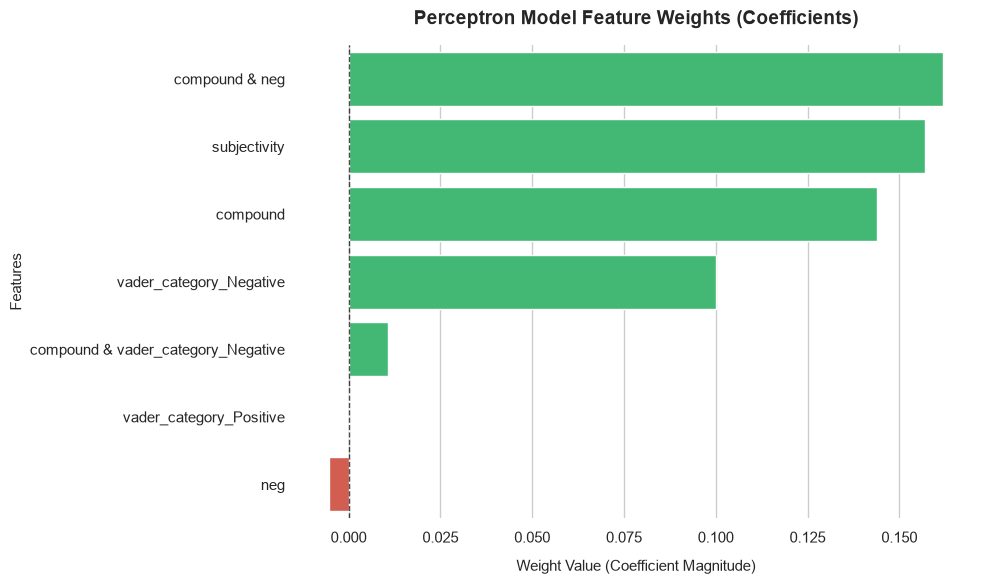

In [53]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Create a DataFrame of feature weights (assumes binary classification)
# If multi-class, select a specific class row: perceptron.coef_[0]
weights_df = pd.DataFrame(
    {"Feature": targets.columns, "Weight": perceptron.coef_.flatten()}
)

# 2. Sort the features by weight for a cleaner visual flow
weights_df = weights_df.sort_values(by="Weight", ascending=False)

# 3. Define colors (optional: distinct colors for positive vs. negative weights)
weights_df["Color"] = np.where(weights_df["Weight"] >= 0, "#2ecc71", "#e74c3c")

# 4. Initialize the plot
plt.figure(figsize=(10, 6), dpi=100)
sns.set_theme(style="whitegrid")

# 5. Create horizontal bar plot (easier to read feature names)
ax = sns.barplot(
    x="Weight",
    y="Feature",
    data=weights_df,
    palette=weights_df["Color"].tolist(),
)

# 6. Add a vertical line at zero to visually anchor the weights
plt.axvline(x=0, color="black", linestyle="--", linewidth=1, alpha=0.7)

# 7. Customize labels and title
plt.title(
    "Perceptron Model Feature Weights (Coefficients)",
    fontsize=14,
    pad=15,
    weight="bold",
)
plt.xlabel("Weight Value (Coefficient Magnitude)", fontsize=11, labelpad=10)
plt.ylabel("Features", fontsize=11)

# 8. Clean up borders and adjust layout
sns.despine(left=True, bottom=True)
plt.tight_layout()

# 9. Show the plot
plt.show()


## Trying to see how rounding influences the Perceptron

In [60]:
targets_rounded = targets.round(6)

X_train, X_test, y_train, y_test = train_test_split(
    targets_rounded, y, test_size=0.2, random_state=42
)

perceptron = Perceptron(max_iter=100, eta0=0.1, random_state=42)
perceptron.fit(X_train, y_train)

y_pred = perceptron.predict(X_test)

class_report = classification_report(
    y_test, y_pred, output_dict=True, zero_division=0
)
# Extract accuracy
accuracy = class_report.pop("accuracy")

# Convert remaining metrics into a DataFrame (typically 4 rows: classes, macro avg, weighted avg)
report_df = pd.DataFrame(class_report).T

# Add accuracy as a column (pandas automatically broadcasts a single scalar value to all rows)
report_df["accuracy"] = accuracy

# Broadcast the list of features to match the number of rows
report_df["features_used"] = [targets.columns.tolist()] * len(report_df)

# Add n_features (pandas automatically broadcasts a single scalar value to all rows)
report_df["n_features"] = 7

report_df


,precision,recall,f1-score,support,accuracy,features_used,n_features
0,0.733333,0.354839,0.478261,31.0,0.606557,"[subjectivity, compound, neg, vader_category_N...",7
1,0.565217,0.866667,0.684211,30.0,0.606557,"[subjectivity, compound, neg, vader_category_N...",7
macro avg,0.649275,0.610753,0.581236,61.0,0.606557,"[subjectivity, compound, neg, vader_category_N...",7
weighted avg,0.650653,0.606557,0.579548,61.0,0.606557,"[subjectivity, compound, neg, vader_category_N...",7
